# FreshFlow — Notebook 03: Model 2 — Ingredient Risk Predictor

**Question:** for each restaurant × ingredient, what is the probability that **some stock is discarded in the next 3 days** (expiry, over-preparation or spoilage)?
**Data:** Dataset 2 (`dataset2_inventory_waste.csv`) + ingredient master.
**Model:** gradient-boosted classifier, with a simple expiry/overstock rule as the baseline.
**Outputs:** risk probability, risk level, expected at-risk quantity, surplus quantity and financial exposure.

Features at day *t* only use stock, usage and discards up to and including *t*. The target looks at days *t+1..t+3*. Train and test are split with a 3-day gap so no target window straddles the cut-off.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve
from sklearn.inspection import permutation_importance

DATA = Path("../data"); MODELS = Path("../models"); OUT = Path("../outputs")
MODELS.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
TRAIN_CUT = pd.Timestamp("2025-06-26")
TEST_START = pd.Timestamp("2025-06-30")

## 1. Load and explore Dataset 2

rows: (24854, 26) | dates: 2024-01-01 to 2025-12-31
stock balance check (max abs residual): 0.001


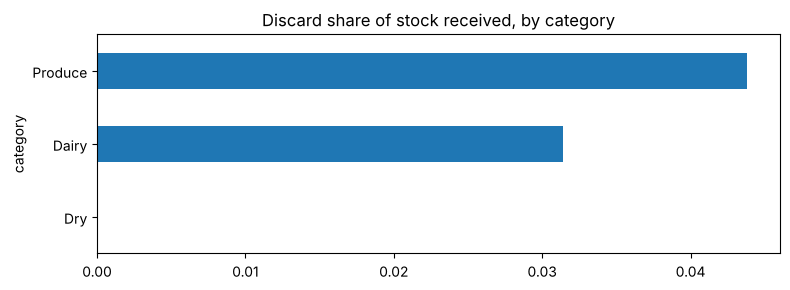

discard_reason
none        20171
overprep     3417
expired      1014
spoilage      252
Name: count, dtype: int64

In [2]:
inv = pd.read_csv(DATA / "dataset2_inventory_waste.csv", parse_dates=["date"])
master = pd.read_csv(DATA / "ingredient_master.csv")
print("rows:", inv.shape, "| dates:", inv.date.min().date(), "to", inv.date.max().date())
print("stock balance check (max abs residual):",
      round((inv.opening_stock_qty + inv.received_qty - inv.expired_discard_qty - inv.spoilage_discard_qty
             - inv.actual_usage_qty - inv.overprep_discard_qty - inv.closing_stock_qty).abs().max(), 4))
disc_by_cat = inv.groupby("category")[["total_discard_qty", "received_qty"]].sum()
(disc_by_cat["total_discard_qty"] / disc_by_cat["received_qty"]).sort_values().plot.barh(
    title="Discard share of stock received, by category", figsize=(8, 3))
plt.tight_layout(); plt.show()
inv.discard_reason.value_counts()

## 2. Feature engineering and target

In [3]:
inv = inv.merge(master[["ingredient_id", "shelf_life_days", "target_cover_days", "supplier_lead_time_days"]],
                on="ingredient_id", how="left")
inv = inv.sort_values(["restaurant_id", "ingredient_id", "date"]).reset_index(drop=True)
g = inv.groupby(["restaurant_id", "ingredient_id"])

inv["usage_1d"] = inv["actual_usage_qty"]
inv["usage_7d_mean"] = g["actual_usage_qty"].transform(lambda s: s.rolling(7, min_periods=3).mean())
inv["usage_14d_sum"] = g["actual_usage_qty"].transform(lambda s: s.rolling(14, min_periods=7).sum())
inv["cover_days"] = (inv["closing_stock_qty"] / inv["usage_7d_mean"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
inv["discard_7d"] = g["total_discard_qty"].transform(lambda s: s.rolling(7, min_periods=1).sum())
inv["discard_14d"] = g["total_discard_qty"].transform(lambda s: s.rolling(14, min_periods=1).sum())
inv["shortage_7d"] = g["shortage_qty"].transform(lambda s: s.rolling(7, min_periods=1).sum())
inv["discard_rate_14d"] = inv["discard_14d"] / (inv["usage_14d_sum"] + inv["discard_14d"]).replace(0, np.nan)

# target: any discard on days t+1, t+2, t+3
disc = g["total_discard_qty"]
fwd = disc.shift(-1).fillna(0) + disc.shift(-2).fillna(0) + disc.shift(-3).fillna(0)
has_window = disc.shift(-3).notna()
inv["future_discard_3d_qty"] = np.where(has_window, fwd, np.nan)
inv["target_waste_next_3d"] = np.where(has_window, (fwd > 0).astype(float), np.nan)

inv["restaurant_code"] = inv["restaurant_id"].astype("category").cat.codes
inv["ingredient_code"] = inv["ingredient_id"].astype("category").cat.codes
inv["category_code"] = inv["category"].astype("category").cat.codes
inv["storage_code"] = inv["storage_type"].astype("category").cat.codes
inv["dow"] = inv["date"].dt.dayofweek
inv["month"] = inv["date"].dt.month
for c in ["min_days_to_expiry", "weighted_remaining_shelf_life_days"]:
    inv[c] = inv[c].astype(float)

FEATURES = ["restaurant_code", "ingredient_code", "category_code", "storage_code", "perishable_flag",
            "shelf_life_days", "closing_stock_qty", "batches_on_hand", "min_days_to_expiry",
            "weighted_remaining_shelf_life_days", "days_since_last_delivery", "pending_order_qty",
            "usage_1d", "usage_7d_mean", "cover_days", "target_cover_days", "discard_7d", "discard_14d",
            "shortage_7d", "discard_rate_14d", "dow", "month"]
CAT_FEATURES = ["restaurant_code", "ingredient_code", "category_code", "storage_code"]
cat_idx = [FEATURES.index(c) for c in CAT_FEATURES]

labelled = inv[inv["target_waste_next_3d"].notna() & inv["usage_7d_mean"].notna()]
train = labelled[labelled["date"] <= TRAIN_CUT]
test = labelled[labelled["date"] >= TEST_START]
print("train:", train.shape, "| test:", test.shape)
print("positive rate train / test:",
      round(train.target_waste_next_3d.mean(), 3), "/", round(test.target_waste_next_3d.mean(), 3))

train: (18394, 45) | test: (6188, 45)
positive rate train / test: 0.39 / 0.388


## 3. Train the classifier

In [4]:
clf = HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
    l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=25,
    categorical_features=cat_idx, random_state=42)
clf.fit(train[FEATURES], train["target_waste_next_3d"].astype(int))
print("trees used:", clf.n_iter_)

trees used: 196


## 4. Evaluate against a rule-based baseline on held-out data

In [5]:
yt = test["target_waste_next_3d"].astype(int).values
p = clf.predict_proba(test[FEATURES])[:, 1]

# rule baseline: the closer the stock is to expiring, the riskier it is
rule_score = -test["min_days_to_expiry"].fillna(999).values
# overstock baseline: stock cover well beyond the target cover
cover_score = test["cover_days"].fillna(0).values

def summarise(score, name):
    return {"model": name, "ROC_AUC": round(roc_auc_score(yt, score), 4),
            "PR_AUC": round(average_precision_score(yt, score), 4)}

res = pd.DataFrame([
    summarise(rule_score, "rule: days-to-expiry"),
    summarise(cover_score, "rule: stock cover days"),
    summarise(p, "gbm classifier (Model 2)"),
])
res.set_index("model")

,ROC_AUC,PR_AUC
model,,
rule: days-to-expiry,0.8777,0.7974
rule: stock cover days,0.2432,0.2629
gbm classifier (Model 2),0.9133,0.8506


In [6]:
brier = brier_score_loss(yt, p)
prec, rec, thr = precision_recall_curve(yt, p)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best_t = thr[np.argmax(f1[:-1])]
at05 = (p >= 0.5).astype(int)
tp = ((at05 == 1) & (yt == 1)).sum(); fp = ((at05 == 1) & (yt == 0)).sum(); fn = ((at05 == 0) & (yt == 1)).sum()
print(f"Brier score: {brier:.4f}")
print(f"At threshold 0.5 -> precision {tp/(tp+fp+1e-9):.3f}, recall {tp/(tp+fn+1e-9):.3f}")
print(f"Best-F1 threshold: {best_t:.3f}")

Brier score: 0.1010
At threshold 0.5 -> precision 0.738, recall 0.932
Best-F1 threshold: 0.211


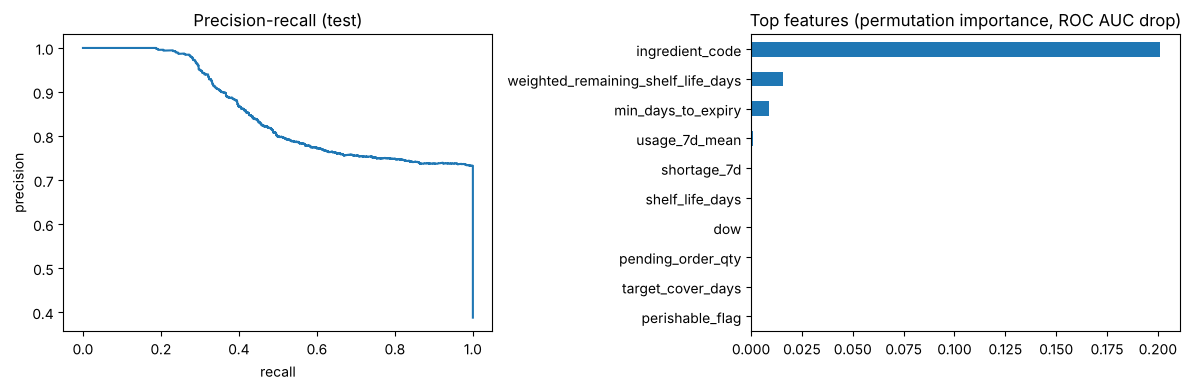

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rec, prec); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall (test)")
imp_sample = test.sample(min(4000, len(test)), random_state=42)
imp = permutation_importance(clf, imp_sample[FEATURES], imp_sample["target_waste_next_3d"].astype(int),
                             scoring="roc_auc", n_repeats=5, random_state=42)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
imp_s.tail(10).plot.barh(ax=ax[1], title="Top features (permutation importance, ROC AUC drop)")
plt.tight_layout(); plt.show()

## 5. Save the model and metrics

In [8]:
joblib.dump(clf, MODELS / "model2_ingredient_risk_gbm.joblib")
json.dump({"features": FEATURES, "categorical_features": CAT_FEATURES,
           "target": "any stock discarded on t+1..t+3", "decision_threshold_0.5": True,
           "best_f1_threshold": round(float(best_t), 4)},
          open(MODELS / "model2_config.json", "w"), indent=2)
json.dump({"test_metrics": res.set_index("model").to_dict(orient="index"),
           "brier": round(float(brier), 4), "best_f1_threshold": round(float(best_t), 4)},
          open(OUT / "metrics_model2.json", "w"), indent=2)
print("saved.")

saved.


## 6. Current risk report (feeds the decision engine)

Scores each restaurant × ingredient using the state at the last recorded day, i.e. risk over the **next three days**. The risk level thresholds are 0.5 (High) and 0.25 (Medium).

In [9]:
as_of = inv["date"].max()
now = inv[inv["date"] == as_of].copy()
now["risk_prob_next_3d"] = clf.predict_proba(now[FEATURES])[:, 1].round(4)
now["risk_level"] = np.select([now["risk_prob_next_3d"] >= 0.5, now["risk_prob_next_3d"] >= 0.25],
                              ["High", "Medium"], "Low")
now["surplus_qty_next_3d"] = (now["closing_stock_qty"] - 3 * now["usage_7d_mean"]).clip(lower=0).round(3)
now["expected_at_risk_qty"] = (now["risk_prob_next_3d"] * now["closing_stock_qty"]).round(3)
now["financial_exposure_inr"] = (now["expected_at_risk_qty"] * now["unit_cost_inr"]).round(2)
now["primary_driver"] = np.select(
    [now["min_days_to_expiry"] <= 3,
     now["cover_days"] > 2 * now["target_cover_days"],
     now["shortage_7d"] > 0],
    ["Expiry", "Overstock", "Shortage history"], "Usage pattern")

risk = now[["restaurant_id", "ingredient_id", "ingredient_name", "category", "unit", "unit_cost_inr",
            "closing_stock_qty", "min_days_to_expiry", "usage_7d_mean", "cover_days",
            "risk_prob_next_3d", "risk_level", "surplus_qty_next_3d", "expected_at_risk_qty",
            "financial_exposure_inr", "primary_driver"]].copy()
risk.insert(0, "as_of_date", as_of.strftime("%Y-%m-%d"))
risk["forecast_window"] = "next 3 days"
risk = risk.sort_values("financial_exposure_inr", ascending=False)
risk.to_csv(OUT / "ingredient_risk_next_day.csv", index=False)
print("risk level counts:", risk["risk_level"].value_counts().to_dict())
risk.head(10)

risk level counts: {'High': 17, 'Low': 16, 'Medium': 1}


,as_of_date,restaurant_id,ingredient_id,ingredient_name,category,unit,unit_cost_inr,closing_stock_qty,min_days_to_expiry,usage_7d_mean,cover_days,risk_prob_next_3d,risk_level,surplus_qty_next_3d,expected_at_risk_qty,financial_exposure_inr,primary_driver,forecast_window
16081,2025-12-31,R02,I05,Butter,Dairy,kg,520,18.145,34.0,1.861429,9.747889,0.5464,High,12.561,9.914,5155.28,Usage pattern,next 3 days
13157,2025-12-31,R02,I01,Paneer,Dairy,kg,380,16.803,4.0,6.270000,2.679904,0.7724,High,0.000,12.979,4932.02,Usage pattern,next 3 days
730,2025-12-31,R01,I01,Paneer,Dairy,kg,380,15.240,4.0,8.692571,1.753221,0.7681,High,0.000,11.706,4448.28,Usage pattern,next 3 days
3654,2025-12-31,R01,I05,Butter,Dairy,kg,520,11.332,49.0,2.382143,4.757061,0.6275,High,4.186,7.111,3697.72,Usage pattern,next 3 days
7309,2025-12-31,R01,I10,Spinach,Produce,kg,60,13.338,0.0,5.576143,2.391976,0.9984,High,0.000,13.317,799.02,Expiry,next 3 days
9502,2025-12-31,R01,I13,Yogurt (Curd),Dairy,kg,90,13.147,1.0,4.994714,2.632183,0.6405,High,0.000,8.421,757.89,Expiry,next 3 days
21929,2025-12-31,R02,I13,Yogurt (Curd),Dairy,kg,90,10.038,6.0,3.775857,2.658469,0.7544,High,0.000,7.573,681.57,Usage pattern,next 3 days
2923,2025-12-31,R01,I04,Fresh Cream,Dairy,kg,420,3.438,4.0,0.808714,4.251192,0.4682,Medium,1.012,1.610,676.20,Usage pattern,next 3 days
8040,2025-12-31,R01,I11,Cauliflower,Produce,kg,50,18.345,4.0,5.872571,3.123845,0.7079,High,0.727,12.986,649.30,Usage pattern,next 3 days
22660,2025-12-31,R02,I14,Mushroom,Produce,kg,180,3.384,0.0,1.323714,2.556443,0.9987,High,0.000,3.380,608.40,Expiry,next 3 days
